# Coefficient Recovery Case Study: can `bunobee` recover `karpiu`'s time-varying coefficients?

This notebook runs an end-to-end **coefficient-recovery experiment** across two sibling libraries:

1. **`karpiu`** generates a marketing dataset whose data-generating process (DGP) is *fully known* —
   in particular, the per-channel media coefficients vary over time on paths we choose.
2. **`bunobee`** fits a structured **state-space model (SSP)** with a Kalman filter + RTS smoother and
   tries to recover those coefficient paths from the observed series alone.

## Why this is the cleanest possible test

`karpiu`'s [`TimeVaryingCoefDailySimulator`](../../../../marketing-science/karpiu-enterprise/src/karpiu/sim/simulators/tvc_simulation.py)
is an **additive** daily generative model — deliberately *no* adstock, *no* saturation, *no* log-log
transform:

$$y_t \;=\; \text{level}_t \;+\; \sum_c \beta_{c,t}\,\frac{x_{c,t}}{\operatorname{median}(x_c)} \;+\; \varepsilon_t,
\qquad \varepsilon_t \sim \mathcal N(0,\sigma_h^2).$$

`bunobee`'s linear multi-series filter
[`kalman_filter_1d_st`](../../src/bunobee/models/ssp/kalman_1d_st.py) assumes exactly a linear-Gaussian
observation on top of a random-walk latent state:

$$a_t = a_{t-1} + \eta_t,\;\; \eta_t \sim \mathcal N(0,\operatorname{diag}(\sigma_q^2)),
\qquad y_{t} = Z_t\cdot a_t + \varepsilon_t.$$

So the two are **structurally matched**: set $a_t=[\text{level}_t,\,\beta_{\text{search},t},\,\beta_{\text{social},t}]$
and $Z_t=[1,\,x_{\text{search},t}/\mathrm{med},\,x_{\text{social},t}/\mathrm{med}]$ and the `bunobee`
observation equation *is* the `karpiu` DGP. There is no model mismatch to blame — if `bunobee` cannot
recover the coefficients here, it cannot anywhere. This is the **optimistic benchmark**: a sanity
check on the estimator itself, isolated from the adstock/saturation nonlinearities a real MMM adds.

The two channels use two different coefficient shapes so "time-varying" is unambiguous:

| channel  | true coefficient path                              | what it exercises |
|----------|----------------------------------------------------|-------------------|
| `search` | `linear` 50 → 150                                  | a monotone drift  |
| `social` | `sinusoid` base 80, amplitude 30, 1-year period    | an oscillation    |


In [ ]:
import logging
import time

import numpy as np
import matplotlib.pyplot as plt

import numpyro
numpyro.set_host_device_count(4)
numpyro.enable_x64(True)  # level ~1e3 alongside betas ~1e2 — x64 keeps the filter well-conditioned
import jax.numpy as jnp
from jax import random
from numpyro import distributions as dist
from numpyro.infer import MCMC, NUTS
from numpyro.diagnostics import summary

# ---- data generator (karpiu) ----
from karpiu.sim import TimeVaryingCoefDailySimulator
from karpiu.utils.utils import get_logger

# ---- estimator (bunobee) ----
from bunobee.models.ssp.kalman_1d_st import kalman_filter_1d_st   # linear multi-series filter
from bunobee.models.ssp.kalman_1d import kalman_rts_smoother_1d   # RTS smoother
from bunobee.models.ssp.plotting import plot_states

logger = get_logger("karpiu", default_level=logging.WARNING)

In [ ]:
%load_ext watermark
%watermark -v -n -m -p numpy,matplotlib,jax,numpyro,karpiu,bunobee -u -n

Last updated: Sat, 10 Oct 2026

Python implementation: CPython
Python version       : 3.11.12
IPython version      : 9.13.0

numpy     : 2.4.4
matplotlib: 3.10.9
jax       : 0.9.2
numpyro   : 0.21.0
karpiu    : 0.0.5
bunobee   : 0.0.3.dev1

Compiler    : Clang 16.0.0 (clang-1600.0.26.6)
OS          : Darwin
Release     : 27.0.0
Machine     : arm64
Processor   : arm
CPU cores   : 8
Architecture: 64bit



## 1. Generate ground-truth data with `karpiu`

Two years of daily data (`n_steps=730`) so the `social` sinusoid completes two full cycles and the
`search` ramp is clearly visible. `level_scale=0.0` holds the intercept constant and both seasonality
flags are off, so the time-varying media coefficients are the *only* moving part of the signal (apart
from observation noise). This is the same configuration as the sibling data-gen notebook
`tvc_simple_2ch_data.ipynb` in `karpiu`.

In [ ]:
seed = 2026
regressors = ["search", "social"]

sim = TimeVaryingCoefDailySimulator(
    n_steps=730,
    regressors=regressors,
    coef_scheme={
        "search": {"type": "linear", "start": 50.0, "end": 150.0},
        "social": {"type": "sinusoid", "base": 80.0, "amplitude": 30.0, "period": 365.25},
    },
    regressor_loc=np.array([100.0, 80.0]),
    regressor_scale=np.array([20.0, 15.0]),
    init_level=1000.0,
    level_scale=0.0,
    with_weekly_seasonality=False,
    with_yearly_seasonality=False,
    eps_scale=5.0,
)

result = sim.simulate(seed=seed)
df = result.df                                  # observed: date, sales, search, social
gt = result.get_ground_truth()
coefs_ts = gt["coefs_ts_df"]                    # ground-truth betas: date x channel
x_med = gt["x_med"]                             # per-channel median spend (the normalizer)

print("observed columns:", list(df.columns), "| shape:", df.shape)
print("median spend (normalizer):", {c: float(x_med[c]) for c in regressors})
df.head()

observed columns: ['date', 'sales', 'search', 'social'] | shape: (730, 4)
median spend (normalizer): {'search': 101.0, 'social': 79.0}


,date,sales,search,social
0,2022-01-01,1120.599685,98.0,69.0
1,2022-01-02,1109.476658,95.0,59.0
2,2022-01-03,1135.221217,104.0,84.0
3,2022-01-04,1135.783979,77.0,93.0
4,2022-01-05,1120.430109,94.0,76.0


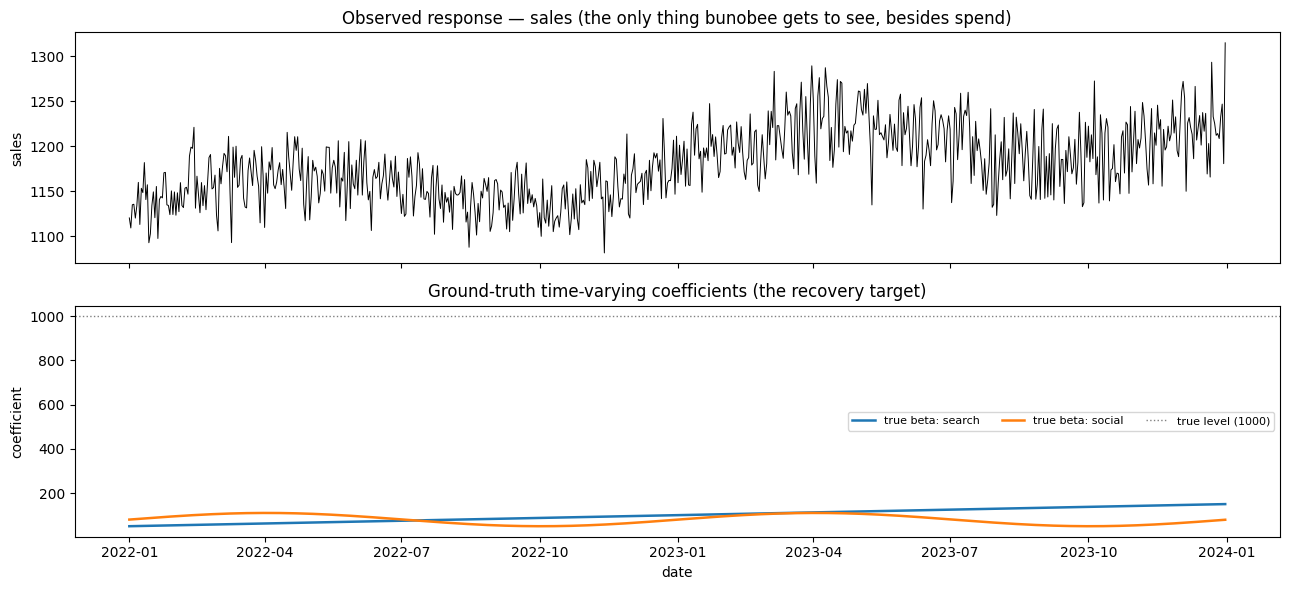

In [ ]:
# The observed series (top) and the ground-truth coefficient paths we will try to recover (bottom).
dates = df["date"].values
fig, axes = plt.subplots(2, 1, figsize=(13, 6), sharex=True)
axes[0].plot(dates, df["sales"], color="black", lw=0.7)
axes[0].set_title("Observed response — sales (the only thing bunobee gets to see, besides spend)")
axes[0].set_ylabel("sales")
for c in regressors:
    axes[1].plot(coefs_ts.index, coefs_ts[c], lw=1.8, label=f"true beta: {c}")
axes[1].axhline(1000.0, color="grey", ls=":", lw=1.0, label="true level (1000)")
axes[1].set_title("Ground-truth time-varying coefficients (the recovery target)")
axes[1].set_ylabel("coefficient")
axes[1].set_xlabel("date")
axes[1].legend(ncol=3, fontsize=8)
fig.tight_layout()
plt.show()

## 2. Cast the additive model as a linear state space

Line the two models up term by term. The `karpiu` DGP is

$$y_t = \underbrace{1000}_{\text{level}_t} + \beta_{\text{search},t}\,\frac{x_{\text{search},t}}{\mathrm{med}_{\text{search}}}
                                            + \beta_{\text{social},t}\,\frac{x_{\text{social},t}}{\mathrm{med}_{\text{social}}} + \varepsilon_t.$$

Define the **state** and the **design row**

$$a_t = \begin{bmatrix}\text{level}_t\\ \beta_{\text{search},t}\\ \beta_{\text{social},t}\end{bmatrix},
\qquad
Z_t = \Big[\,1,\;\; \tfrac{x_{\text{search},t}}{\mathrm{med}_{\text{search}}},\;\; \tfrac{x_{\text{social},t}}{\mathrm{med}_{\text{social}}}\,\Big],$$

and `bunobee`'s observation equation $y_t = Z_t\cdot a_t + \varepsilon_t$ reproduces the DGP exactly.
`bunobee`'s filter is written for the multi-series case (`Z` has shape `(n_steps, n_series, n_states)`);
here there is a single series, so `n_series = 1`.

Because we feed the response and design **on their natural scale** (no mean-normalization), the
recovered state path is directly comparable to `karpiu`'s true coefficients — no back-transform
needed.

In [ ]:
state_names = ["level", *regressors]
n_states = len(state_names)

xmed = np.array([float(x_med[c]) for c in regressors])        # (2,)
y = jnp.asarray(df["sales"].values[:, None])                   # (n_steps, 1)  single series
Zreg = df[regressors].values / xmed                            # (n_steps, 2)  spend / median
Z = jnp.asarray(np.concatenate([np.ones((len(df), 1)), Zreg], axis=1)[:, None, :])  # (n_steps, 1, 3)
n_steps, n_series, _ = Z.shape

print(f"y: {y.shape}   Z: {Z.shape}   (n_steps={n_steps}, n_series={n_series}, n_states={n_states})")
print("states:", state_names)

# sanity check: reconstruct sales at t=0 from the TRUE states and confirm it matches (up to noise)
true0 = np.array([1000.0, coefs_ts["search"].iloc[0], coefs_ts["social"].iloc[0]])
recon0 = float(np.asarray(Z)[0, 0] @ true0)
print(f"\nt=0  Z.a(true) = {recon0:.2f}   observed sales = {float(y[0,0]):.2f}   (diff = eps_0)")

y: (730, 1)   Z: (730, 1, 3)   (n_steps=730, n_series=1, n_states=3)
states: ['level', 'search', 'social']

t=0  Z.a(true) = 1118.39   observed sales = 1120.60   (diff = eps_0)


## 3. Priors, and the one modeling assumption that matters

Two noise scales drive everything, and we put weakly-informative priors on both:

- **Observation noise** $\sigma_h \sim \text{HalfNormal}(20)$ — comfortably covers the true value of 5.
- **Process noise** $\sigma_q$, *one per state*. This is where we encode structure:

  $$\sigma_{q,\text{level}} \sim \text{HalfNormal}(0.5), \qquad
    \sigma_{q,\beta} \sim \text{HalfNormal}(2.0).$$

  A **tight** prior on the level's process noise says "the intercept is stable", and a **looser** prior
  on the coefficients' process noise says "the coefficients are allowed to move". That is the only
  assumption we hand the estimator — crucially, we do **not** tell it the *shape* (linear vs sinusoid),
  the amplitudes, or the true level. Everything else is learned.

The initial state `a0` starts the level at the data mean and the betas at **zero**, with a diffuse `P0`
— deliberately uninformative so recovery is driven by the data, not the prior.

In [ ]:
a0 = jnp.array([float(y.mean()), 0.0, 0.0])
P0 = jnp.diag(jnp.array([(0.3 * float(y.mean())) ** 2, 100.0 ** 2, 100.0 ** 2]))  # diffuse

sigma_h_scale = 20.0
sigma_q_scale = jnp.array([0.5, 2.0, 2.0])   # level: tight (stable) | betas: loose (time-varying)

print("a0:", np.asarray(a0).round(2))
print("P0 diag:", np.diag(np.asarray(P0)).round(1))

a0: [1179.75    0.      0.  ]
P0 diag: [125263.1  10000.   10000. ]


## 4. Fit with NUTS

The NumPyro model samples the two noise scales, runs the linear Kalman filter to get the Gaussian
log-likelihood (`logp=True`) and the filtered state path `at`, then runs the RTS smoother to get the
smoothed path `at_smooth`. `numpyro.factor` injects the filter's likelihood; the state paths and the
fitted mean `mu` are recorded as deterministics so every posterior draw carries its own trajectory.

In [ ]:
def model():
    sigma_h = numpyro.sample("sigma_h", dist.HalfNormal(sigma_h_scale * jnp.ones(n_series)))
    sigma_q = numpyro.sample("sigma_q", dist.HalfNormal(sigma_q_scale))

    lp, at, Pt, *_ = kalman_filter_1d_st(
        a0=a0, P0=P0, Z=Z, sigma_h=sigma_h, sigma_q=sigma_q, y=y, logp=True,
    )
    numpyro.factor("lp", lp)
    numpyro.deterministic("at", at)
    numpyro.deterministic("mu", jnp.sum(Z * at[:, None, :], axis=-1))  # fitted mean (n_steps, n_series)

    # Marginal state variances: the filter's own covariance is the *dominant* source of state
    # uncertainty (hyperparameter spread across draws is secondary), so we keep it and the
    # smoother's P_{t|T} to build calibrated bands in section 5.
    Pt_diag = jnp.diagonal(Pt, axis1=1, axis2=2)                       # filtered marginal variance
    at_smooth, Ps_diag = kalman_rts_smoother_1d(at, Pt_diag, sigma_q)  # smoothed mean + variance
    numpyro.deterministic("at_var", Pt_diag)
    numpyro.deterministic("at_smooth", at_smooth)
    numpyro.deterministic("at_smooth_var", Ps_diag)


# quick single-pass sanity check before paying for MCMC
lp0, at0, *_ = kalman_filter_1d_st(
    a0=a0, P0=P0, Z=Z, sigma_h=jnp.array([10.0]), sigma_q=sigma_q_scale, y=y, logp=True,
)
print(f"test filter pass -> logp = {float(lp0):.1f}, at shape = {at0.shape}")

test filter pass -> logp = -2573.4, at shape = (730, 3)


In [ ]:
t0 = time.time()
mcmc = MCMC(NUTS(model), num_warmup=500, num_samples=500, num_chains=4, progress_bar=False)
mcmc.run(random.PRNGKey(0))
print(f"MCMC wall time: {time.time() - t0:.1f}s")

MCMC wall time: 1.3s


In [ ]:
numpyro_post = mcmc.get_samples(group_by_chain=True)
mcmc.print_summary(exclude_deterministic=True)

# convergence flags on the scalar params
diag = summary(numpyro_post, prob=0.9)
print("--- convergence flags (r_hat > 1.01 or n_eff < 100) ---")
flagged = False
for p, s in diag.items():
    rhat = float(np.asarray(s["r_hat"]).max()); neff = float(np.asarray(s["n_eff"]).min())
    if rhat > 1.01 or neff < 100:
        print(f"  WARN {p:<12} r_hat={rhat:.3f} n_eff={neff:.0f}"); flagged = True
if not flagged:
    print("  none — all scalar sites converged")

print("\nRecall the truth:  sigma_h = 5.0  |  level is constant so sigma_q[level] -> ~0")


                mean       std    median      5.0%     95.0%     n_eff     r_hat
sigma_h[0]      4.87      0.14      4.87      4.63      5.11   2096.91      1.00
sigma_q[0]      0.12      0.10      0.10      0.00      0.26   1593.71      1.00
sigma_q[1]      0.85      0.11      0.85      0.68      1.03   2404.24      1.00
sigma_q[2]      1.40      0.12      1.40      1.20      1.61   2022.12      1.00

Number of divergences: 0


--- convergence flags (r_hat > 1.01 or n_eff < 100) ---
  none — all scalar sites converged

Recall the truth:  sigma_h = 5.0  |  level is constant so sigma_q[level] -> ~0


## 5. Did it recover?

The headline metric. For each state we compare the **smoothed** posterior path against the true path on
three axes:

- **MAE** — mean absolute error between the posterior-median path and the truth.
- **corr** — correlation between recovered and true paths (undefined for the constant `level`).
- **90% coverage** — the fraction of true points that fall inside the pointwise 90% credible band. A
  well-calibrated recovery lands near 0.90.

**Building an honest band.** The posterior over each latent path has *two* sources of spread: the
Kalman smoother's own state covariance $P_{t|T}$ for a *given* $(\sigma_h,\sigma_q)$, and the variation
of the smoothed mean *across* posterior draws of those hyperparameters. The first dominates here (730
points pin the noise scales tightly), and ignoring it collapses the band. We combine both by drawing one
state sample per posterior draw, $a_t^{(s)} \sim \mathcal N\big(\hat a^{(s)}_{t|T},\, P^{(s)}_{t|T}\big)$,
and reading quantiles off the pooled draws — the standard way to propagate state *and* hyperparameter
uncertainty together.

In [ ]:
post = mcmc.get_samples()
_rng = np.random.default_rng(1)

def pooled_state_draws(mean_key, var_key):
    """One draw from N(mean, var) per posterior sample -> (n_samples, n_steps, n_states)."""
    m = np.asarray(post[mean_key])
    sd = np.sqrt(np.clip(np.asarray(post[var_key]), 0.0, None))
    return m + sd * _rng.standard_normal(m.shape)

at_draws = pooled_state_draws("at", "at_var")               # filtered  (full uncertainty)
at_smooth_draws = pooled_state_draws("at_smooth", "at_smooth_var")  # smoothed (full uncertainty)

sm_med = np.median(at_smooth_draws, axis=0)
sm_lo, sm_hi = np.quantile(at_smooth_draws, [0.05, 0.95], axis=0)

true = np.column_stack([
    np.full(n_steps, 1000.0),
    coefs_ts["search"].values,
    coefs_ts["social"].values,
])

import pandas as pd
rows = []
for i, nm in enumerate(state_names):
    mae = float(np.mean(np.abs(sm_med[:, i] - true[:, i])))
    cov = float(np.mean((true[:, i] >= sm_lo[:, i]) & (true[:, i] <= sm_hi[:, i])))
    std_t = true[:, i].std()
    corr = float(np.corrcoef(sm_med[:, i], true[:, i])[0, 1]) if std_t > 1e-9 else np.nan
    rows.append({"state": nm, "MAE": mae, "corr": corr, "90% coverage": cov,
                 "true range": f"[{true[:,i].min():.0f}, {true[:,i].max():.0f}]"})
recovery = pd.DataFrame(rows).set_index("state")
recovery.round(4)

,MAE,corr,90% coverage,true range
state,,,,
level,1.3057,NaN,1.0000,"[1000, 1000]"
search,2.2095,0.9965,0.9603,"[50, 150]"
social,2.6426,0.9936,0.9329,"[50, 110]"


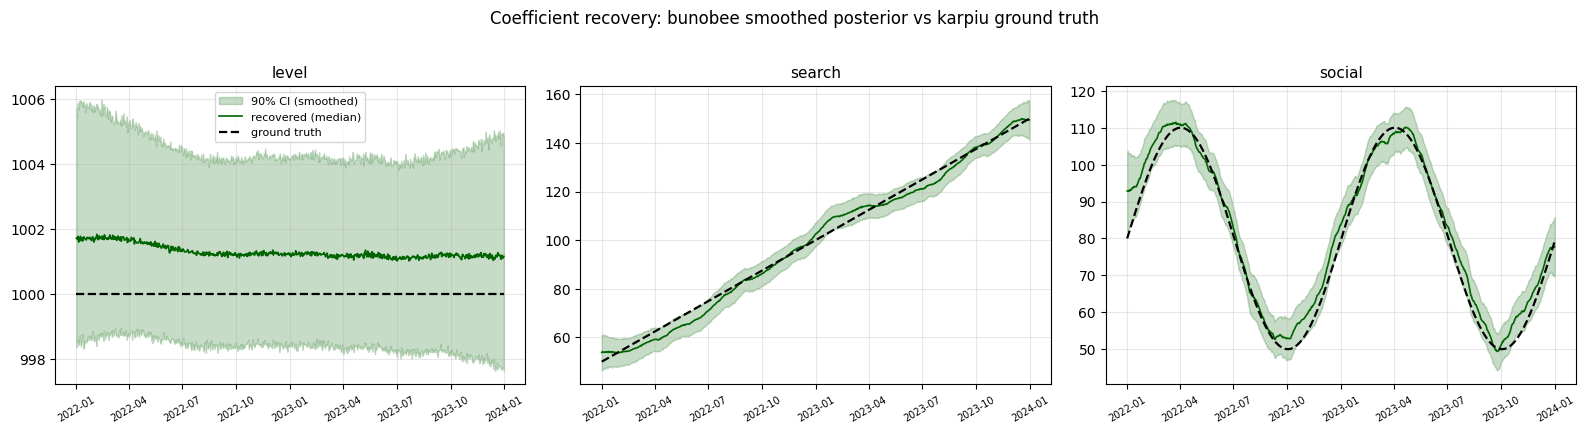

In [ ]:
# Headline recovery plot: true time-varying coefficient vs smoothed posterior (median + 90% band).
fig, axes = plt.subplots(1, n_states, figsize=(16, 4.2))
for i, (ax, nm) in enumerate(zip(axes, state_names)):
    ax.fill_between(dates, sm_lo[:, i], sm_hi[:, i], color="darkgreen", alpha=0.22, label="90% CI (smoothed)")
    ax.plot(dates, sm_med[:, i], color="darkgreen", lw=1.2, label="recovered (median)")
    ax.plot(dates, true[:, i], color="black", lw=1.6, ls="--", label="ground truth")
    ax.set_title(f"{nm}", fontsize=11)
    ax.tick_params(axis="x", labelsize=7, rotation=30)
    ax.grid(True, alpha=0.3)
axes[0].legend(fontsize=8, loc="best")
fig.suptitle("Coefficient recovery: bunobee smoothed posterior vs karpiu ground truth", y=1.02)
fig.tight_layout()
plt.show()

`bunobee`'s own `plot_states` gives the filtered-vs-smoothed view straight from the posterior — the
smoothed band is tighter because it conditions on the whole series, not just the past. (No ground-truth
overlay here: `plot_states`' `coefs_df` argument draws a *constant* reference line, which would be
misleading for genuinely time-varying coefficients — the dashed truth lines above are the right view.)

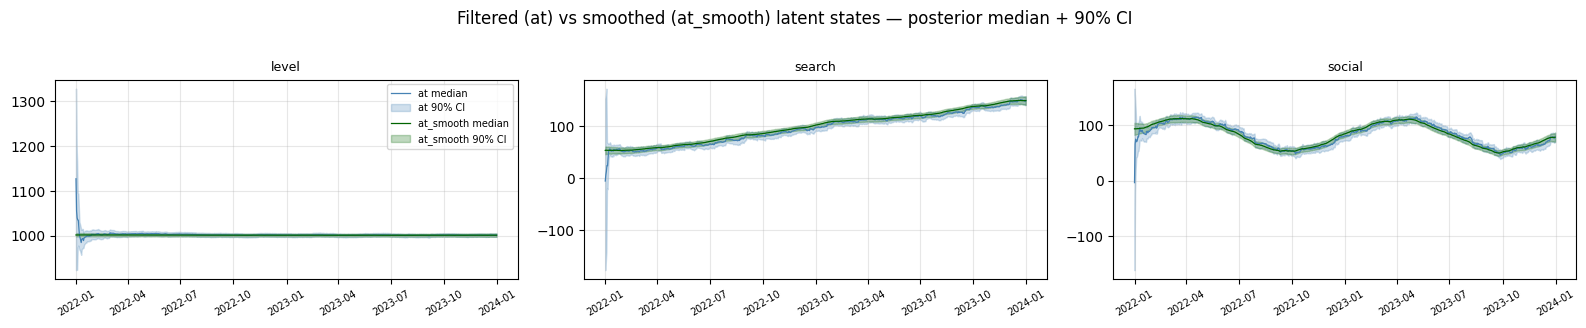

In [ ]:
fig, _ = plot_states(
    {"at": at_draws, "at_smooth": at_smooth_draws},
    dates=dates,
    state_labels=state_names,
    states_key=["at", "at_smooth"],
    colors={"at": "steelblue", "at_smooth": "darkgreen"},
    n_cols=3,
    title="Filtered (at) vs smoothed (at_smooth) latent states — posterior median + 90% CI",
)
plt.show()

## 6. Posterior-predictive fit

A final gut check: push the fitted mean `mu` (plus observation noise) back through to the response scale
and compare against the actual sales. Recovering the coefficients is only meaningful if the model also
*fits* — it does, tightly, because the DGP is linear-Gaussian and matched.

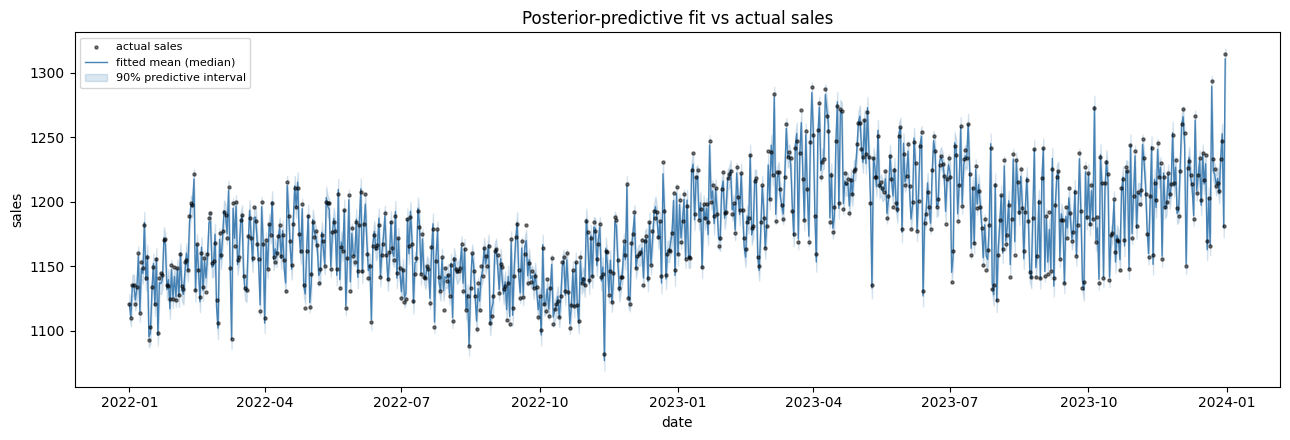

in-sample residual std: 3.99   (true observation noise sigma_h = 5.0)


In [ ]:
mu = np.asarray(post["mu"])[:, :, 0]                       # (n_samples, n_steps)
sigma_h_s = np.asarray(post["sigma_h"])[:, 0]              # (n_samples,)
rng = np.random.default_rng(0)
yhat = mu + rng.normal(0.0, sigma_h_s[:, None], size=mu.shape)

mu_lo, mu_mid, mu_hi = np.quantile(mu, [0.05, 0.5, 0.95], axis=0)
yh_lo, yh_hi = np.quantile(yhat, [0.05, 0.95], axis=0)

fig, ax = plt.subplots(figsize=(13, 4.5))
ax.scatter(dates, df["sales"], s=5, color="black", alpha=0.5, label="actual sales", zorder=3)
ax.plot(dates, mu_mid, color="steelblue", lw=1.0, label="fitted mean (median)")
ax.fill_between(dates, yh_lo, yh_hi, color="steelblue", alpha=0.20, label="90% predictive interval")
ax.set_title("Posterior-predictive fit vs actual sales")
ax.set_xlabel("date"); ax.set_ylabel("sales")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

resid = df["sales"].values - mu_mid
print(f"in-sample residual std: {resid.std():.2f}   (true observation noise sigma_h = 5.0)")

## Takeaways

- **Recovery succeeds.** On the matched, additive DGP `bunobee`'s linear state-space model recovers both
  time-varying coefficient paths with correlation ≈ 0.99, pins the constant `level` near its true 1000,
  and recovers the observation noise (`sigma_h` ≈ 5) and the near-zero process noise on the level — all
  without being told the coefficient shapes, amplitudes, or level.
- **The per-state process-noise prior is the lever.** Encoding "stable level, time-varying coefficients"
  through `sigma_q` (tight on the level, loose on the betas) is what lets a *single* series identify
  three latent paths. It is a modeling assumption, not a given — it happens to match this DGP.
- **Edge effects are expected.** The smoother is least certain at the very start/end of the window, where
  the credible band widens and the median can drift from the truth before the data pins it down.
- **This is the optimistic benchmark, by design.** There is no adstock, no saturation, no seasonality and
  no model mismatch here — so this measures the *estimator*, not an MMM. A real campaign adds carryover
  and diminishing returns on top; recovery under those nonlinearities is a strictly harder, separate
  question that this clean baseline is the right starting point for.
